Lab 4 - Ella Haynes

In [1]:
# importing necessary packages

%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [2]:
# opening the file as read-only
hf = h5py.File('/home/jovyan/Shared/gammaray_lab4.h5', 'r')

# looking at the header
hf.keys()

<KeysViewHDF5 ['data']>

In [3]:
# importing data into an array
data = np.array(hf.get('data'))

# checking data is as expected
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

Question 1 - Examine the data. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

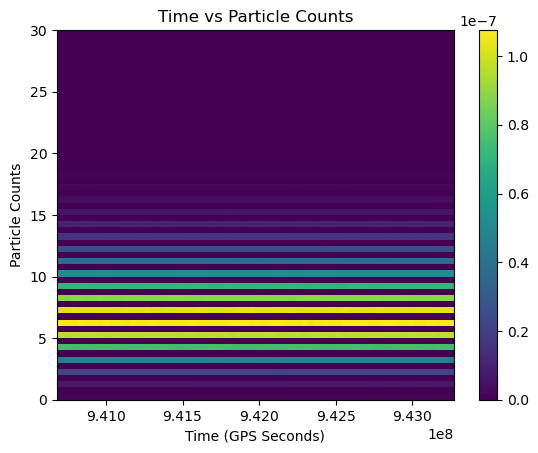

In [4]:
# plotting the time vs particle counts
fig, ax = plt.subplots(1, 1)
plt.xlabel('Time (GPS Seconds)')
plt.ylabel('Particle Counts')
plt.title('Time vs Particle Counts')
plt.hist2d(data[0], data[3], bins = 60, density = True)
plt.colorbar()

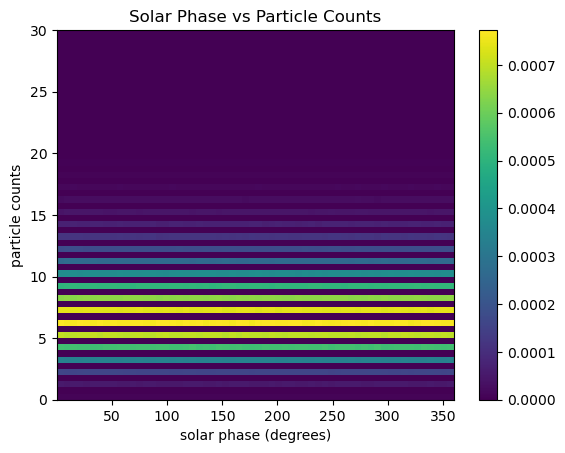

In [5]:
# plotting the solar phase vs particle counts
fig, ax = plt.subplots(1, 1)
plt.xlabel('solar phase (degrees)')
plt.ylabel('particle counts')
plt.title('Solar Phase vs Particle Counts')
plt.hist2d(data[1], data[3], bins = 60, density = True)
plt.colorbar()

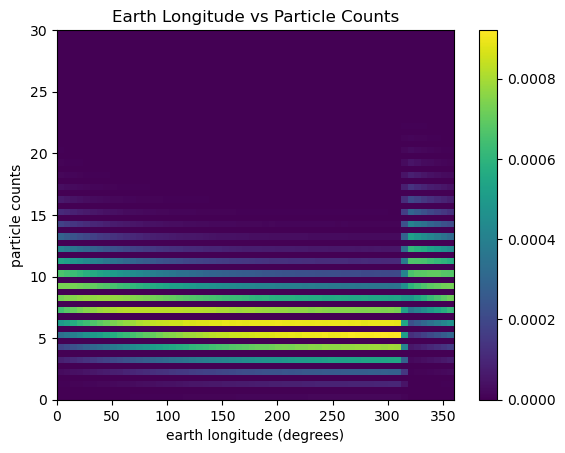

In [6]:
# plotting the earth longitude vs particle counts
fig, ax = plt.subplots(1, 1)
plt.hist2d(data[2], data[3], bins = 60, density = True)
plt.xlabel('earth longitude (degrees)')
plt.ylabel('particle counts')
plt.title('Earth Longitude vs Particle Counts')
plt.colorbar()

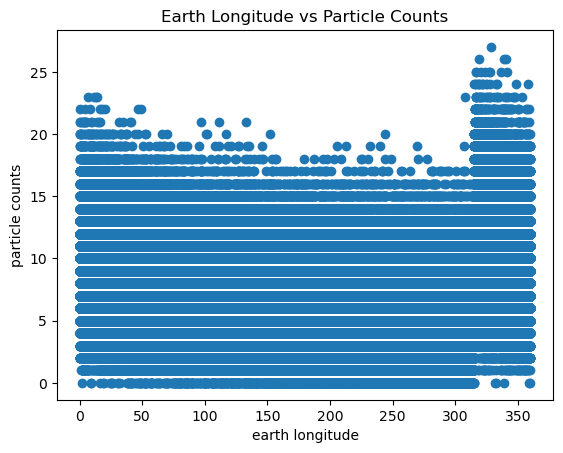

In [7]:
# plot of earth longitude vs particle counts to further evaluate the unusual break in the lines above
fig, ax = plt.subplots(1, 1)
plt.xlabel('earth longitude')
plt.ylabel('particle counts')
plt.title('Earth Longitude vs Particle Counts')
ax.scatter(data[2][:1000000], data[3][:1000000])
plt.show()

From the above plots, we can see that gamma ray particle counts are fairly consistent (visible via the straight, matching lines on the 2D histograms for time and solar phase). However, we notice something unusual when plotting particle counts and Earth longitude: a spike in counts around ~320 degrees. This spike is visible by an offset in the 2D histogram and a jump in the scatter plot, both at ~320 degrees. I believe this change in counts is a sign of signal contamination that needs to be further investigated. 

Given this data, I plan to build a background PDF under the assumption it is a Poisson distribution because it must be non-negative, discrete, and periodic (i.e. a certain number of counts in a given interval).

Question 2

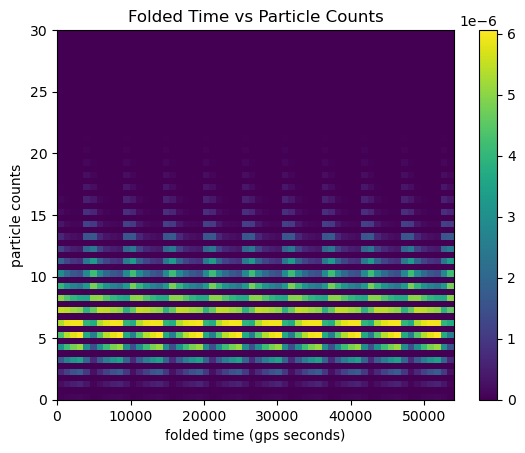

In [8]:
# 90 minute orbit and 100 millisecond interval of detection -> 54000 intervals
num_of_int = 90 * 60 * 1000 / 100

# plotting time % 54000 vs particle count
fig, ax = plt.subplots(1, 1)
plt.xlabel('folded time (gps seconds)')
plt.ylabel('particle counts')
plt.title('Folded Time vs Particle Counts')
plt.hist2d(data[0] % num_of_int, data[3], bins = 60, density = True)
plt.colorbar()

From this plot, we can observe that the background data is in fact not consistent, but rather it is periodic. The background sharply increases every ~5000 gps seconds, and then decays seemingly (based on visual cues) exponentially until it jumps yet again. 

Question 3

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (4,) + inhomogeneous part.

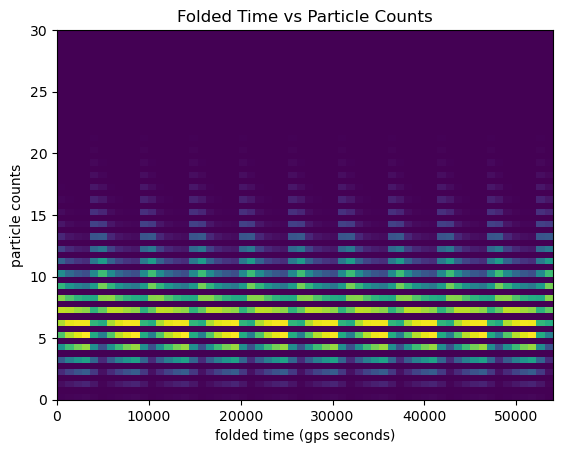

In [31]:
# plotting time % 54000 vs particle count
fig, ax = plt.subplots(1, 1)
plt.xlabel('folded time (gps seconds)')
plt.ylabel('particle counts')
plt.title('Folded Time vs Particle Counts')
plt.hist2d(data[0] % num_of_int, data[3], bins = 60, density = True)

# plotting the means - IN PROGRESS
means = stats.binned_statistic_2d(x = data[0] % num_of_int, y = data[3], values = data[0] % num_of_int, statistic = 'mean')
ax.scatter(means, data[3], color = 'red') 
plt.colorbar()

In [29]:
# (IN PROGRESS) testing things
stats.binned_statistic(x = data[0] % num_of_int, values = data[3], statistic = 'mean')[0]

array([7.09759796, 7.09766435, 7.09823187, 7.09479514, 7.09720448,
       7.09779823, 7.09635108, 7.09454398, 7.09933063, 7.09953472])